# Práctica guiada — Inferencia y contratos

Este notebook es para el alumnado. Completa las celdas marcadas con `TODO` y responde las preguntas antes de mirar la solución docente.

**Objetivo:** pasar de una fila CSV a una especificación clara para el módulo de inferencia de la clase 2.

## Cómo trabajar

1. Copia esta carpeta como tu espacio de trabajo.
2. Ejecuta `uv sync` desde `problem/starter/` cuando empiece la clase 2.
3. En esta práctica no implementes todavía el CLI completo.
4. Trabaja en parejas y cambia quién escribe cada diez minutos.
5. No abras `solutions/` hasta el debrief.

In [27]:
from dataclasses import dataclass
import csv
from pathlib import Path

from pydantic import BaseModel, ConfigDict, Field, ValidationError

DATA_PATH = Path("../assets/03-wine-quality/inference_samples.csv")
print(DATA_PATH)
print(DATA_PATH.exists())

../assets/03-wine-quality/inference_samples.csv
True


## 1. Leer los datos nuevos

### Práctica A — Inspección del CSV

Completa la celda siguiente para:

- Leer el CSV con `csv.DictReader`.
- Imprimir el número de filas.
- Imprimir las columnas.
- Guardar la primera fila en una variable llamada `row`.

In [28]:
# TODO: implementa la lectura del CSV.
# Pista: usa DATA_PATH.open(newline="", encoding="utf-8")
#1.-Leer el csv con DictReader
with DATA_PATH.open(newline="",encoding="utf-8") as csvfile:
    reader = csv.DictReader(csvfile)
    rows = list(reader) 

#Cada fila del csv es un diccionario compuesto por claves y valores({"sample_id": "red-001", "fixed_acidity": "7.4", "alcohol": "9.4",...})

#2.-Imprimir el número de filas 
print(f"Número de filas: {len(rows)}")

#3.-Numero de columnas e imprimirlas,y guardar la primera fila en una variable llamada `row`.

#La primera línea del CSV (la cabecera) no cuenta como fila. DictReader la usa solo para poner nombre a las claves,
# por eso salen 5 filas y no 6.
print(f"Número de columnas: {len(rows[0])}")
#4.-Guardar la primera fila en una variable llamada `row`
row = rows[0] #guardamos la primera fila en una variable para poder acceder a sus claves
nombre_columnas = list(row.keys())
print(f"Columnas: {nombre_columnas}")



Número de filas: 5
Número de columnas: 12
Columnas: ['sample_id', 'fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'ph', 'sulphates', 'alcohol']


Explicaciones para entenderlo bien:
Imagina que reader es un dedo que va siguiendo las filas del CSV de una en una. No guarda las filas, solo las va leyendo según avanza. Cuando llega al final, ya no queda nada por leer.
list(reader) hace que el dedo recorra todas las filas y las apunte en una lista (rows).Va dentro del with porque, al salir del bloque, el archivo se cierra.

In [29]:
#Para poder responder a las preguntas de abajo hay que inspeccionar las filas del csv,con lo que tenemos arriba solo vemos 
# los nombres de las columnas y el numero de filas

#Cuantas caracteristics numericas hay?Vamos a ver los valores del diccionario:
print(row.values()) #vemos los valores de la primera fila, que son todos strings, pero algunos son numeros y otros no
#Para responder el resto de preguntas tenemos que ver la siguiente parte,la del contrato


dict_values(['red-001', '7.4', '0.7', '0.0', '1.9', '0.076', '11.0', '34.0', '0.9978', '3.51', '0.56', '9.4'])


### Preguntas

1. ¿Qué campo identifica la muestra pero no es una característica del modelo?

Ese campo es el sample_id

2. ¿Cuántas características numéricas hay?

Hay 11 caracteristicas numericas, lo vemos arriba viendo el valor de los values de cada key del diccionario

3. ¿Qué columna extra añadirías para probar el contrato?

Como hemos puesto model_config = ConfigDict(extra="forbid"),cualquier columna extra que queramos incluir serviria para comprobar que el contrato no deja ponerla

4. ¿Qué valor de `ph` sería claramente inválido?

Como en el contrato hemos puesto que ph :float = Field(ge=2.5,le=4.5), un valor claramente invalido seria 67,por ejemplo

## 2. Construir el contrato con Pydantic

El contrato del modelo contiene estas características:

| Campo | Rango orientativo |
|---|---|
| `fixed_acidity` | 0–20 |
| `volatile_acidity` | 0–2 |
| `citric_acid` | 0–2 |
| `residual_sugar` | 0–20 |
| `chlorides` | 0–1 |
| `free_sulfur_dioxide` | 0–100 |
| `total_sulfur_dioxide` | 0–300 |
| `density` | 0.98–1.01 |
| `ph` | 2.5–4.5 |
| `sulphates` | 0–3 |
| `alcohol` | 5–20 |

In [30]:
# NOTA TEORICA DE REPASO ANTES DE EMPEZAR
# CONTRATO DE DATOS
# Un contrato es una lista de reglas que fija cómo tiene que ser un dato
# para que el modelo lo acepte.
#
# Aquí el contrato dice:
#   - qué campos tiene que traer (las 11 medidas del vino)
#   - de qué tipo es cada uno (números)
#   - entre qué valores es razonable (por ejemplo, el ph entre 2.5 y 4.5)
#   - que no se permite ningún campo de más
#
# Si algo no cumple, se rechaza ANTES de llegar al modelo.
# Así evitamos que el modelo haga una predicción con datos mal puestos
# y que nadie se dé cuenta del error.

In [31]:
class WineQualityRequestPydantic(BaseModel):
    # TODO: prohíbe campos extra con model_config.
    model_config = ConfigDict(extra="forbid")
    # TODO: declara las 11 características con Field(ge=..., le=...).
    fixed_acidity :float  = Field(ge=0,le=20)
    volatile_acidity : float  =  Field(ge=0, le=2)
    citric_acid : float  = Field(ge=0, le=2)
    residual_sugar :float = Field(ge=0, le=20)
    chlorides :float = Field(ge=0,le=1)
    free_sulfur_dioxide :float = Field(ge=0,le=100)
    total_sulfur_dioxide :float = Field(ge=0,le=300)
    density: float =Field(ge=0.98, le=1.01)
    ph: float =Field(ge=2.5, le=4.5)
    sulphates: float = Field(ge=0, le=3)
    alcohol: float =Field(ge=5, le=20)

    
    pass

# TODO: separa sample_id de la fila y valida solo las características del modelo.

model_row = dict(row)  #guardo una copia de la primera fila(en forma de diccionario) para no perderla
#.pop("clave") hace dos cosas a la vez: quita esa clave del diccionario y te devuelve su valor.
sample_id = model_row.pop("sample_id")  #quito la clave sample_id del diccionario y guardo su valor en sample_id
request = WineQualityRequestPydantic.model_validate(model_row)

#para comprobar que todo ha ido bien, imprimimos el sample_id y el request, y el tipo de request.alcohol
print(sample_id)
print(request)
print(type(request.alcohol))
print(request.alcohol)

red-001
fixed_acidity=7.4 volatile_acidity=0.7 citric_acid=0.0 residual_sugar=1.9 chlorides=0.076 free_sulfur_dioxide=11.0 total_sulfur_dioxide=34.0 density=0.9978 ph=3.51 sulphates=0.56 alcohol=9.4
<class 'float'>
9.4


### Práctica B — Validación

Completa una prueba para cada caso:

- Una fila válida.
- Una columna `unexpected_field`.
- Un `ph` fuera de rango.

Antes de ejecutar, escribe qué error esperas.

In [32]:
# TODO: completa los casos y captura ValidationError.
#1.-Una fila válida.
try:
    request = WineQualityRequestPydantic.model_validate(model_row)
    print(f"Fila válida: {request} \n")

except ValidationError as error:
    print(error)

#2.-Una columna `unexpected_field`.

#Creamos una copia de la fila que si que pasaba y le añadimos una columna random a ver si la acepta(no deberia)
model_row_unex = model_row.copy()
model_row_unex["fila no valida"] = 2.0
try:
    request = WineQualityRequestPydantic.model_validate(model_row_unex)
    print(f"Fila válida: {request}\n")
except ValidationError as error:
    print(error)

#espero un error que sea InvalidRowError o algo asi

#3.-Un ph fuera de rango.
model_row_phmalo = model_row.copy()
model_row_phmalo["ph"] = 67.0
try:
    request = WineQualityRequestPydantic.model_validate(model_row_phmalo)
    print(f"Fila válida: {request}\n")
except ValidationError as error:
    print(error)

#Espero un error del tipo InvalidValueError o algo asi

Fila válida: fixed_acidity=7.4 volatile_acidity=0.7 citric_acid=0.0 residual_sugar=1.9 chlorides=0.076 free_sulfur_dioxide=11.0 total_sulfur_dioxide=34.0 density=0.9978 ph=3.51 sulphates=0.56 alcohol=9.4 

1 validation error for WineQualityRequestPydantic
fila no valida
  Extra inputs are not permitted [type=extra_forbidden, input_value=2.0, input_type=float]
    For further information visit https://errors.pydantic.dev/2.13/v/extra_forbidden
1 validation error for WineQualityRequestPydantic
ph
  Input should be less than or equal to 4.5 [type=less_than_equal, input_value=67.0, input_type=float]
    For further information visit https://errors.pydantic.dev/2.13/v/less_than_equal


## 3. Comparar con `dataclass`

Construye la misma estructura con `dataclass`. No añadas todavía validación manual: observa qué garantiza Python y qué no garantiza.

In [33]:
@dataclass(frozen=True, slots=True)
class WineQualityRequestDataclass:
    # TODO: declara las mismas 11 características.
    fixed_acidity:float
    volatile_acidity: float
    citric_acid: float
    residual_sugar: float
    chlorides: float
    free_sulfur_dioxide: float
    total_sulfur_dioxide: float
    density: float
    ph: float
    sulphates: float
    alcohol: float


# TODO: crea una instancia válida y prueba qué ocurre con ph=99.0
model_row_pruebaDataclass = model_row.copy()
model_row_pruebaDataclass["ph"]=99.0

#con la fila normal(ph en rango)
try:
    request_dataclass_phnormal = WineQualityRequestDataclass(**model_row)
    print(f"Fila válida: {request_dataclass_phnormal}\n")
except ValidationError as error:
    print(error)    

#Nota:Qué hace **: desempaqueta un diccionario como argumentos con nombre. Estas dos líneas son equivalentes:
#Clase(**{"ph": 3.5, "alcohol": 9.4})
#Clase(ph=3.5, alcohol=9.4)

#con ph=99
try:
    request_dataclass_ph99 = WineQualityRequestDataclass(**model_row_pruebaDataclass)
    print(f"Aceptada con ph=99.0: {request_dataclass_ph99}\n")
except ValidationError as error:
    print(error)


#NOTA:DATACLASS NO HACE VALIDACION DE NINGUN TIPO!!
# Dataclass: crea una clase que guarda los 11 datos con su nombre (muestra.alcohol, muestra.ph...).
# Python escribe solo el código para crearla(EL __init__), y con frozen=True los datos no se pueden cambiar después.
# NO comprueba rangos ni convierte tipos: acepta ph=99.0 y deja los valores como strings.
# Por eso se valida antes con Pydantic y la dataclass solo se usa con datos ya validados.

Fila válida: WineQualityRequestDataclass(fixed_acidity='7.4', volatile_acidity='0.7', citric_acid='0.0', residual_sugar='1.9', chlorides='0.076', free_sulfur_dioxide='11.0', total_sulfur_dioxide='34.0', density='0.9978', ph='3.51', sulphates='0.56', alcohol='9.4')

Aceptada con ph=99.0: WineQualityRequestDataclass(fixed_acidity='7.4', volatile_acidity='0.7', citric_acid='0.0', residual_sugar='1.9', chlorides='0.076', free_sulfur_dioxide='11.0', total_sulfur_dioxide='34.0', density='0.9978', ph=99.0, sulphates='0.56', alcohol='9.4')



### Decisión de diseño

Completa la frase:

> Usaría Pydantic en la entrada del csv porque es ahí donde tengo que VALIDAR que los datos tengan la estructura que yo quiero(sin columnas extras,el orden que quiero,el tipo del que tienen que ser las variables,valores dentro de los rangos que yo quiero...). 
##No entiendo para que sirve dataclass la verdad
>Usaría `dataclass` en el interior del modulo con los datos ya validados porque solo necesito guardarlos en un objeto con nombres fijos (muestra.alcohol) y que no se pueda modificar, ya que no valida nada..

## 4. Definir el orden del vector

El modelo no recibe un diccionario. Recibe una lista numérica con un orden estable.

In [34]:
print(request)

fixed_acidity=7.4 volatile_acidity=0.7 citric_acid=0.0 residual_sugar=1.9 chlorides=0.076 free_sulfur_dioxide=11.0 total_sulfur_dioxide=34.0 density=0.9978 ph=3.51 sulphates=0.56 alcohol=9.4


In [35]:
# TODO: rellena el orden exacto a partir del CSV y del contrato.
FEATURE_NAMES = (
    "fixed_acidity",
    "volatile_acidity",
    "citric_acid",
    "residual_sugar",
    "chlorides",
    "free_sulfur_dioxide",
    "total_sulfur_dioxide",
    "density",
    "ph",
    "sulphates",
    "alcohol"
)

# TODO: construye vector usando getattr(request, name).
vector = [getattr(request, name) for name in FEATURE_NAMES]
print(vector)

#Es lo mismo que hacerlo con un bucle,que me parece mucho mas comprensible y facil de leer, aunque mas largo
 #vector = []                          # 1. empiezo con una lista vacía
 #
 #for name in FEATURE_NAMES:           # 2. recorro los nombres, uno a uno, EN ORDEN
 #    valor = getattr(request, name)   # 3. leo el valor de ese nombre en request
 #    vector.append(valor)             # 4. lo añado al final de la lista

[7.4, 0.7, 0.0, 1.9, 0.076, 11.0, 34.0, 0.9978, 3.51, 0.56, 9.4]


### Práctica C — Error de orden

Intercambia mentalmente `density` y `alcohol`. Responde:

- ¿El vector sigue teniendo 11 valores?

Si,cambiar los valores de sitio no añade ni quita ninguno

- ¿El clasificador detectaría necesariamente el error?

No,porque al modelo le damos una lista de 11 numeros y no sabe como se llaman.No salta ningún error, predice igual, pero con los datos mal colocados.

- ¿Cómo evitarías que cada script definiera un orden distinto?

Definiendo una variable(en la que se guarden las variables con los nombres en orden ) una sola vez en un unico sitio(en un único archivo) como hemos hecho con FEATURE_NAMES,y que el resto de scripts lo importen en vez de crear su propia fila 

## 5. Contrato de salida

Diseña la estructura que devolverá el módulo. Debe permitir responder:

- ¿Qué muestra se ha procesado?
- ¿Qué categoría se ha predicho?
- ¿Con qué confianza?
- ¿Qué versión de modelo y preprocesado se utilizaron?

In [ ]:
from typing import Literal

class WineQualityPredictionPydantic(BaseModel):
    # TODO: declara los campos de salida y sus restricciones.
 
    #¿Qué muestra se ha procesado?
    sample_id :str =Field(min_length=1)

    #¿Qué categoría se ha predicho?
    quality_band: Literal["needs_review", "acceptable", "excellent"]

    #¿Con qué confianza? 
    confidence: float = Field(ge=0, le=1)

    #¿Qué versión de modelo se utilizó?
    model_version: str = Field(min_length=1)

    #¿Qué versión de preprocesado se utilizó?
    preprocessing_version: str = Field(min_length=1)

    

# TODO: escribe un ejemplo de salida para red-001.
#esto tampoco lo entiendo bien

ejemplo_red_001 = WineQualityPredictionPydantic(
    sample_id="red-001",
    quality_band="acceptable",
    confidence=0.62,
    model_version="wine-quality-rf-v1",
    preprocessing_version="wine-red-features-v1",
)
print(ejemplo_red_001)


sample_id='red-001' quality_band='acceptable' confidence=0.62 model_version='wine-quality-rf-v1' preprocessing_version='wine-red-features-v1'


## 6. Demo del docente: observar la inferencia

El docente ejecutará el notebook resuelto y el comando de referencia. Mientras tanto, anota el recorrido:

```text
CSV → contrato → preprocesado → modelo cargado → predicción
```

No copies la implementación. Tu código de producción empieza en la clase 2 con el starter.

## Entrega

Entrega una captura o exportación con:

- La tabla de contrato.
- Las respuestas de las prácticas A, B y C.
- El orden de las 11 características.
- Un ejemplo de entrada inválida.
- Un contrato de salida.
- Tu plan de implementación para `contracts.py`, `preprocess.py`, `inference.py` y `predict_file.py`.

## TABLA DE CONTRATO

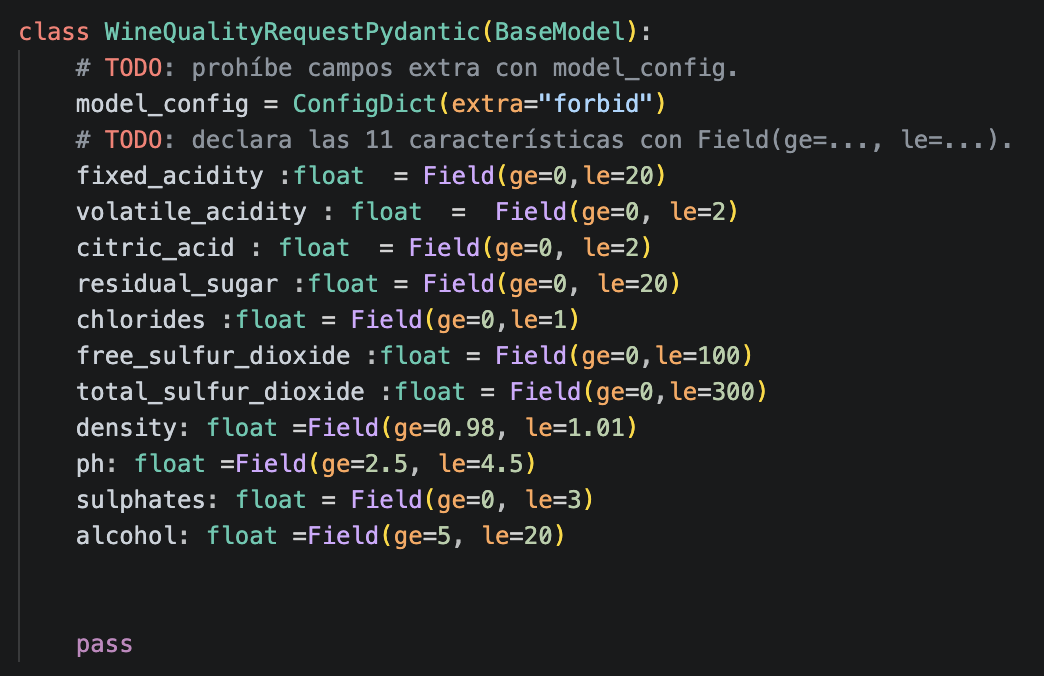

| Variable | Tipo | Unidad | Rango válido | ¿Admite valores ausentes? |
|---|---|---|---|---|
| fixed_acidity | float | g/dm³ | 0 a 20 | No, es obligatoria |
| volatile_acidity | float | g/dm³ | 0 a 2 | No, es obligatoria |
| citric_acid | float | g/dm³ | 0 a 2 | No, es obligatoria |
| residual_sugar | float | g/dm³ | 0 a 20 | No, es obligatoria |
| chlorides | float | g/dm³ | 0 a 1 | No, es obligatoria |
| free_sulfur_dioxide | float | mg/dm³ | 0 a 100 | No, es obligatoria |
| total_sulfur_dioxide | float | mg/dm³ | 0 a 300 | No, es obligatoria |
| density | float | g/cm³ | 0.98 a 1.01 | No, es obligatoria |
| ph | float | sin unidad | 2.5 a 4.5 | No, es obligatoria |
| sulphates | float | g/dm³ | 0 a 3 | No, es obligatoria |
| alcohol | float | % vol. | 5 a 20 | No, es obligatoria |

Además: `sample_id` (texto, no vacío) identifica la muestra y no entra al modelo.Hemos restringidos las columnas extra 
Nota:tabla hecha con ia porque no entendia muy bien que me estaban pidiendo

## RESPUESTAS A,B Y C (EN ESE ORDEN)

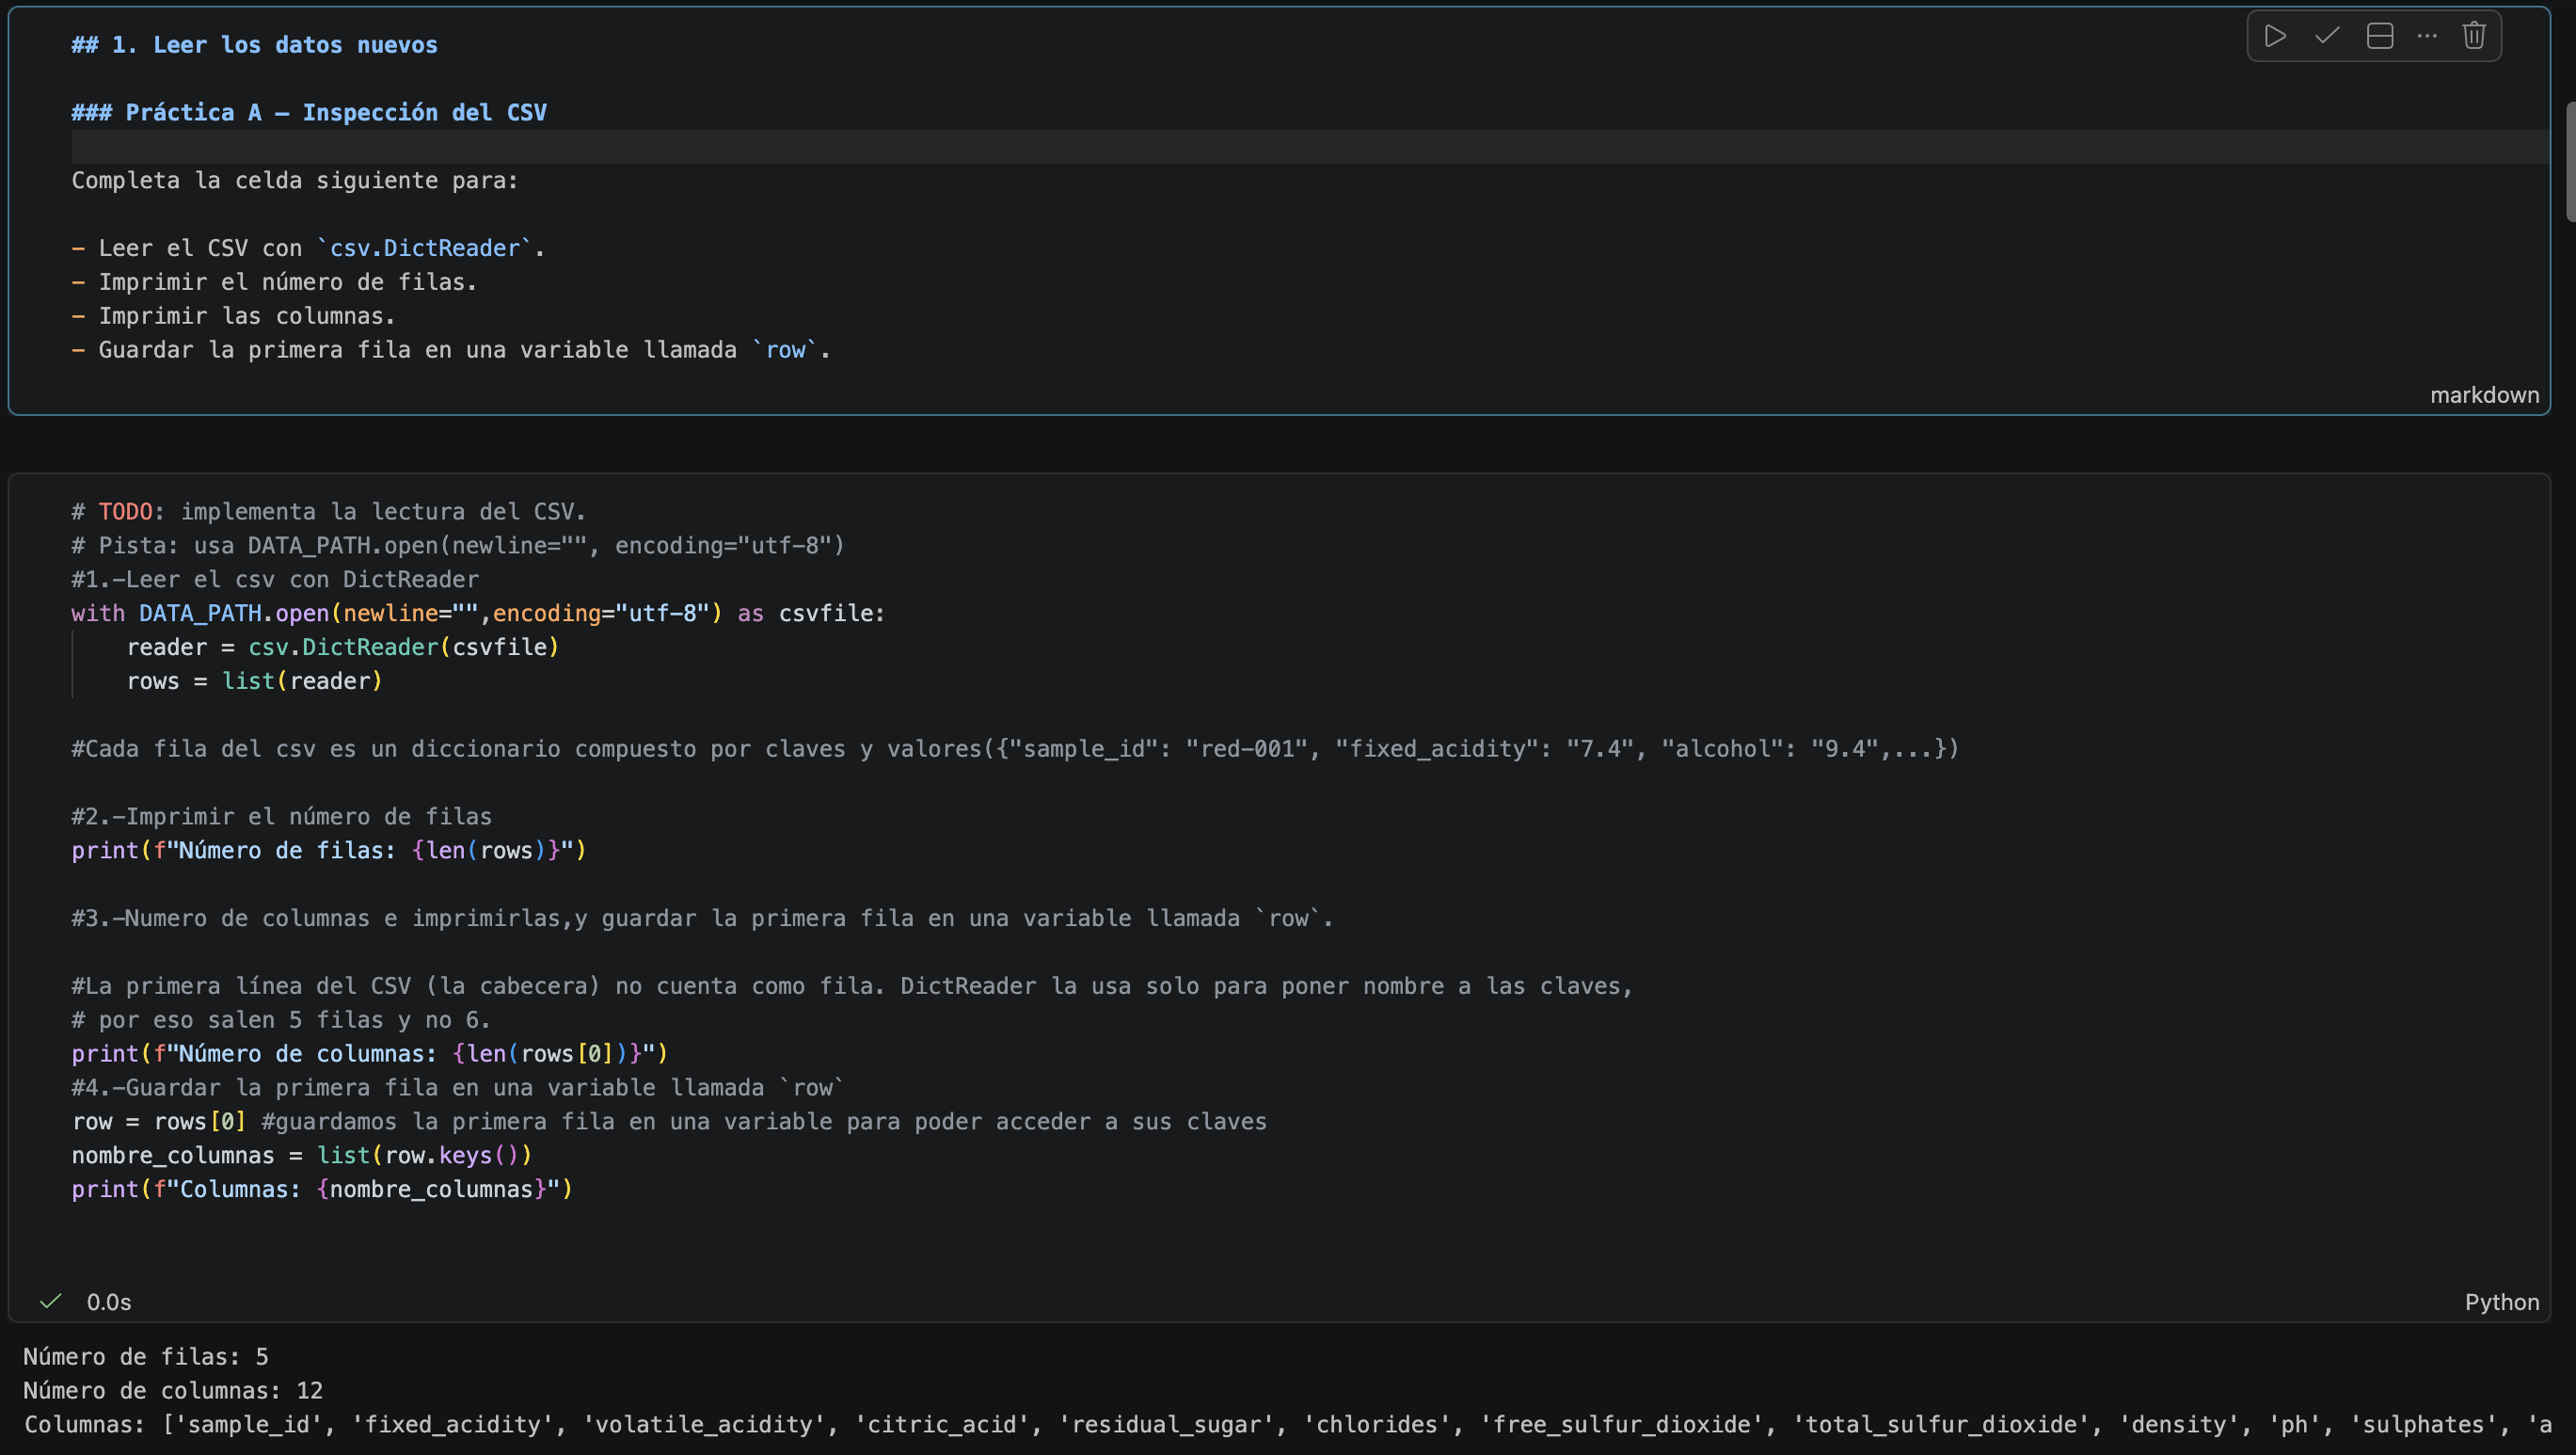

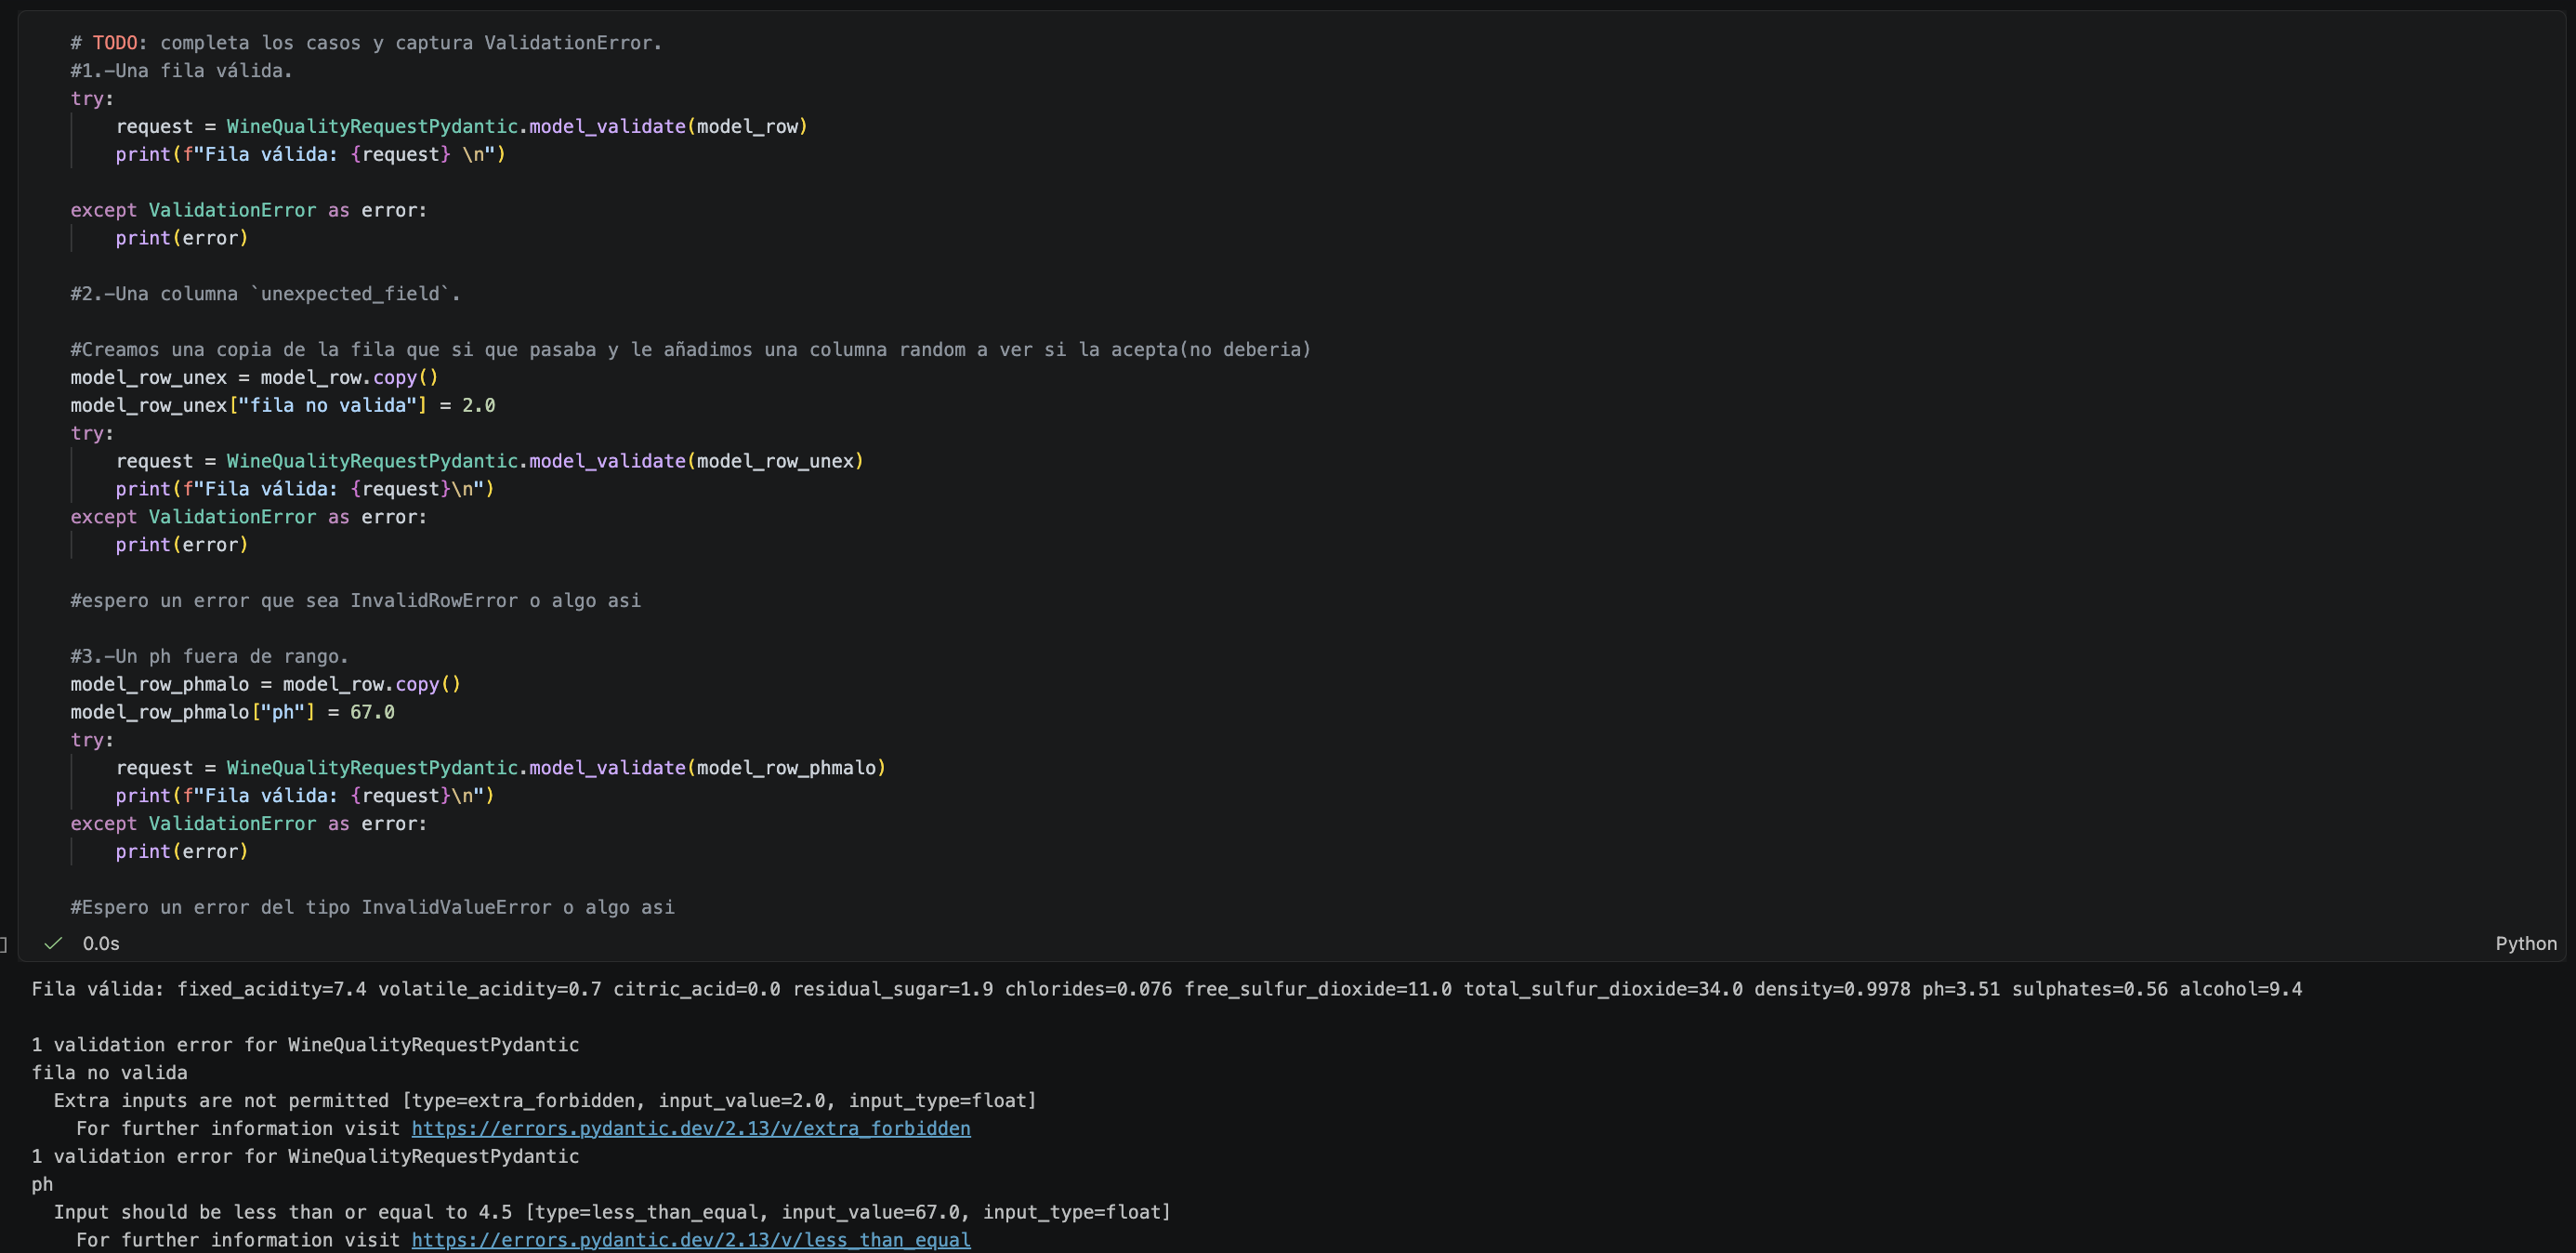

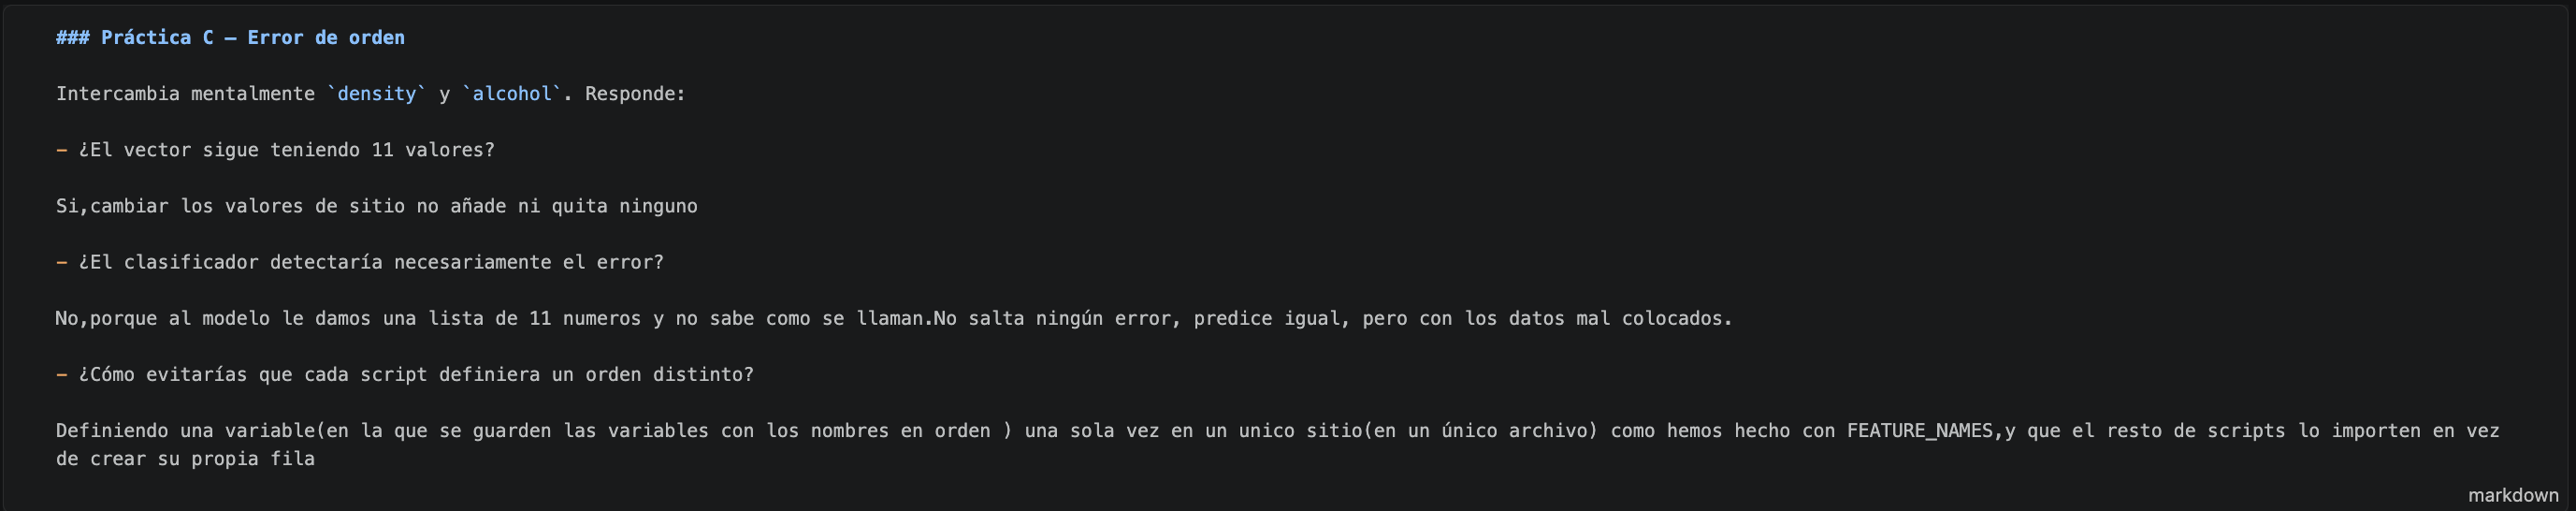

## ORDEN DE LAS 11 CARACTERISTICAS

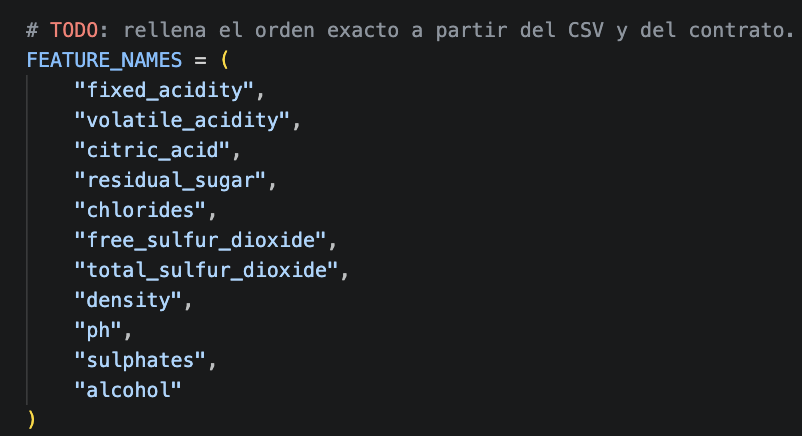

## EJEMPLO DE ENTRADA INVALIDA

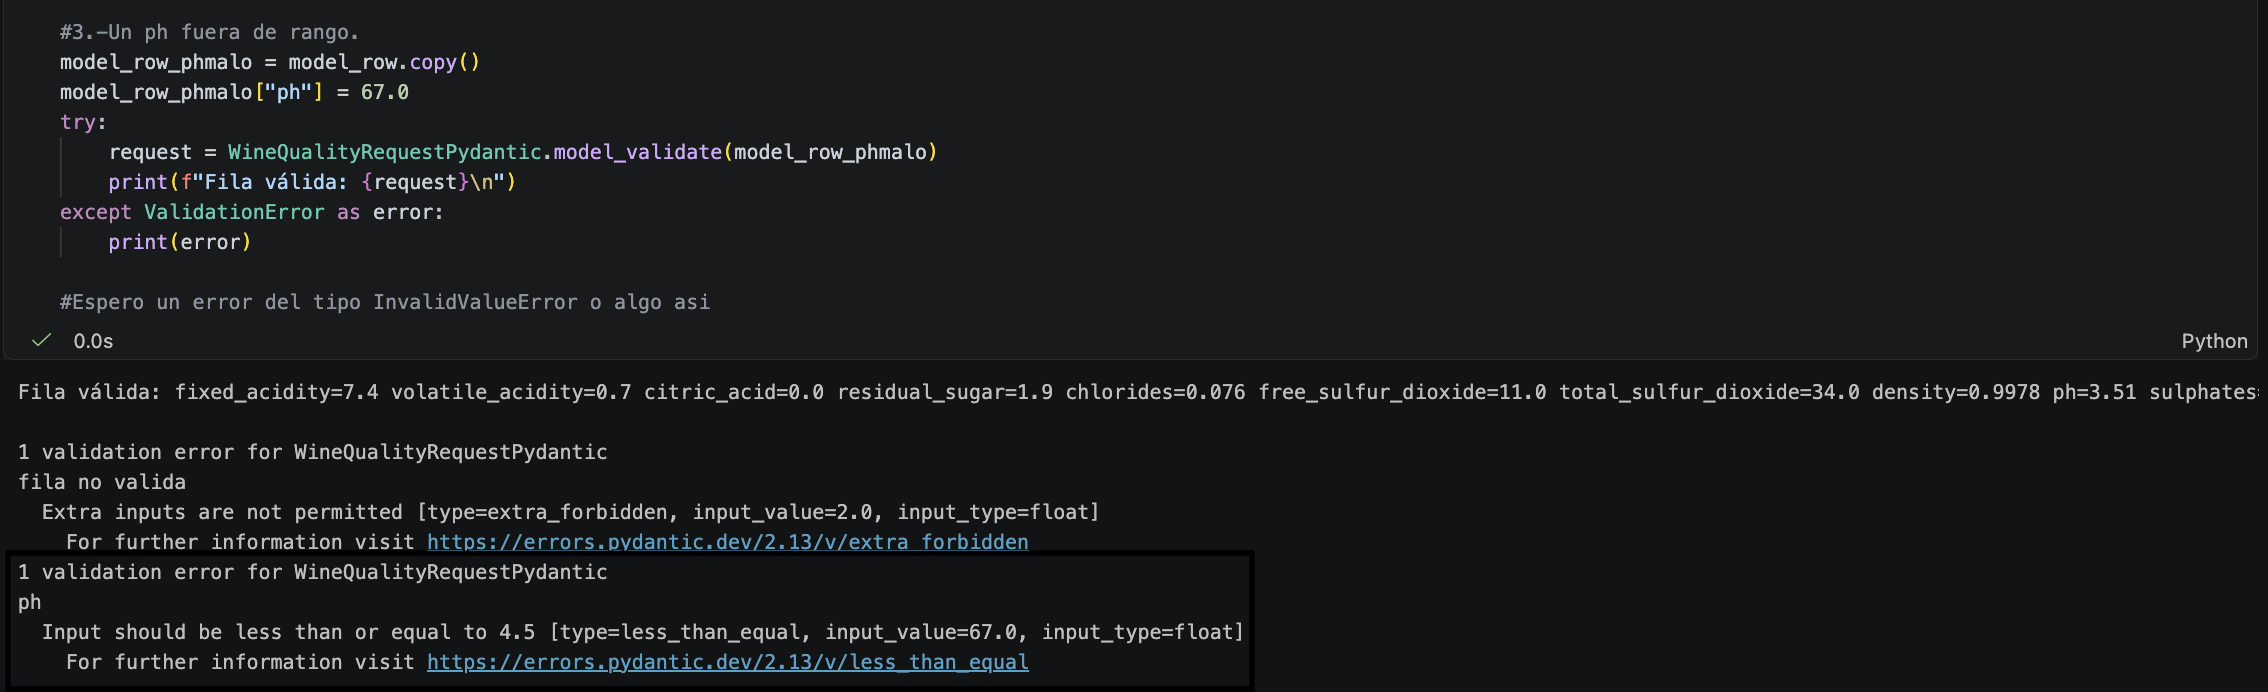

## CONTRATO DE SALIDA

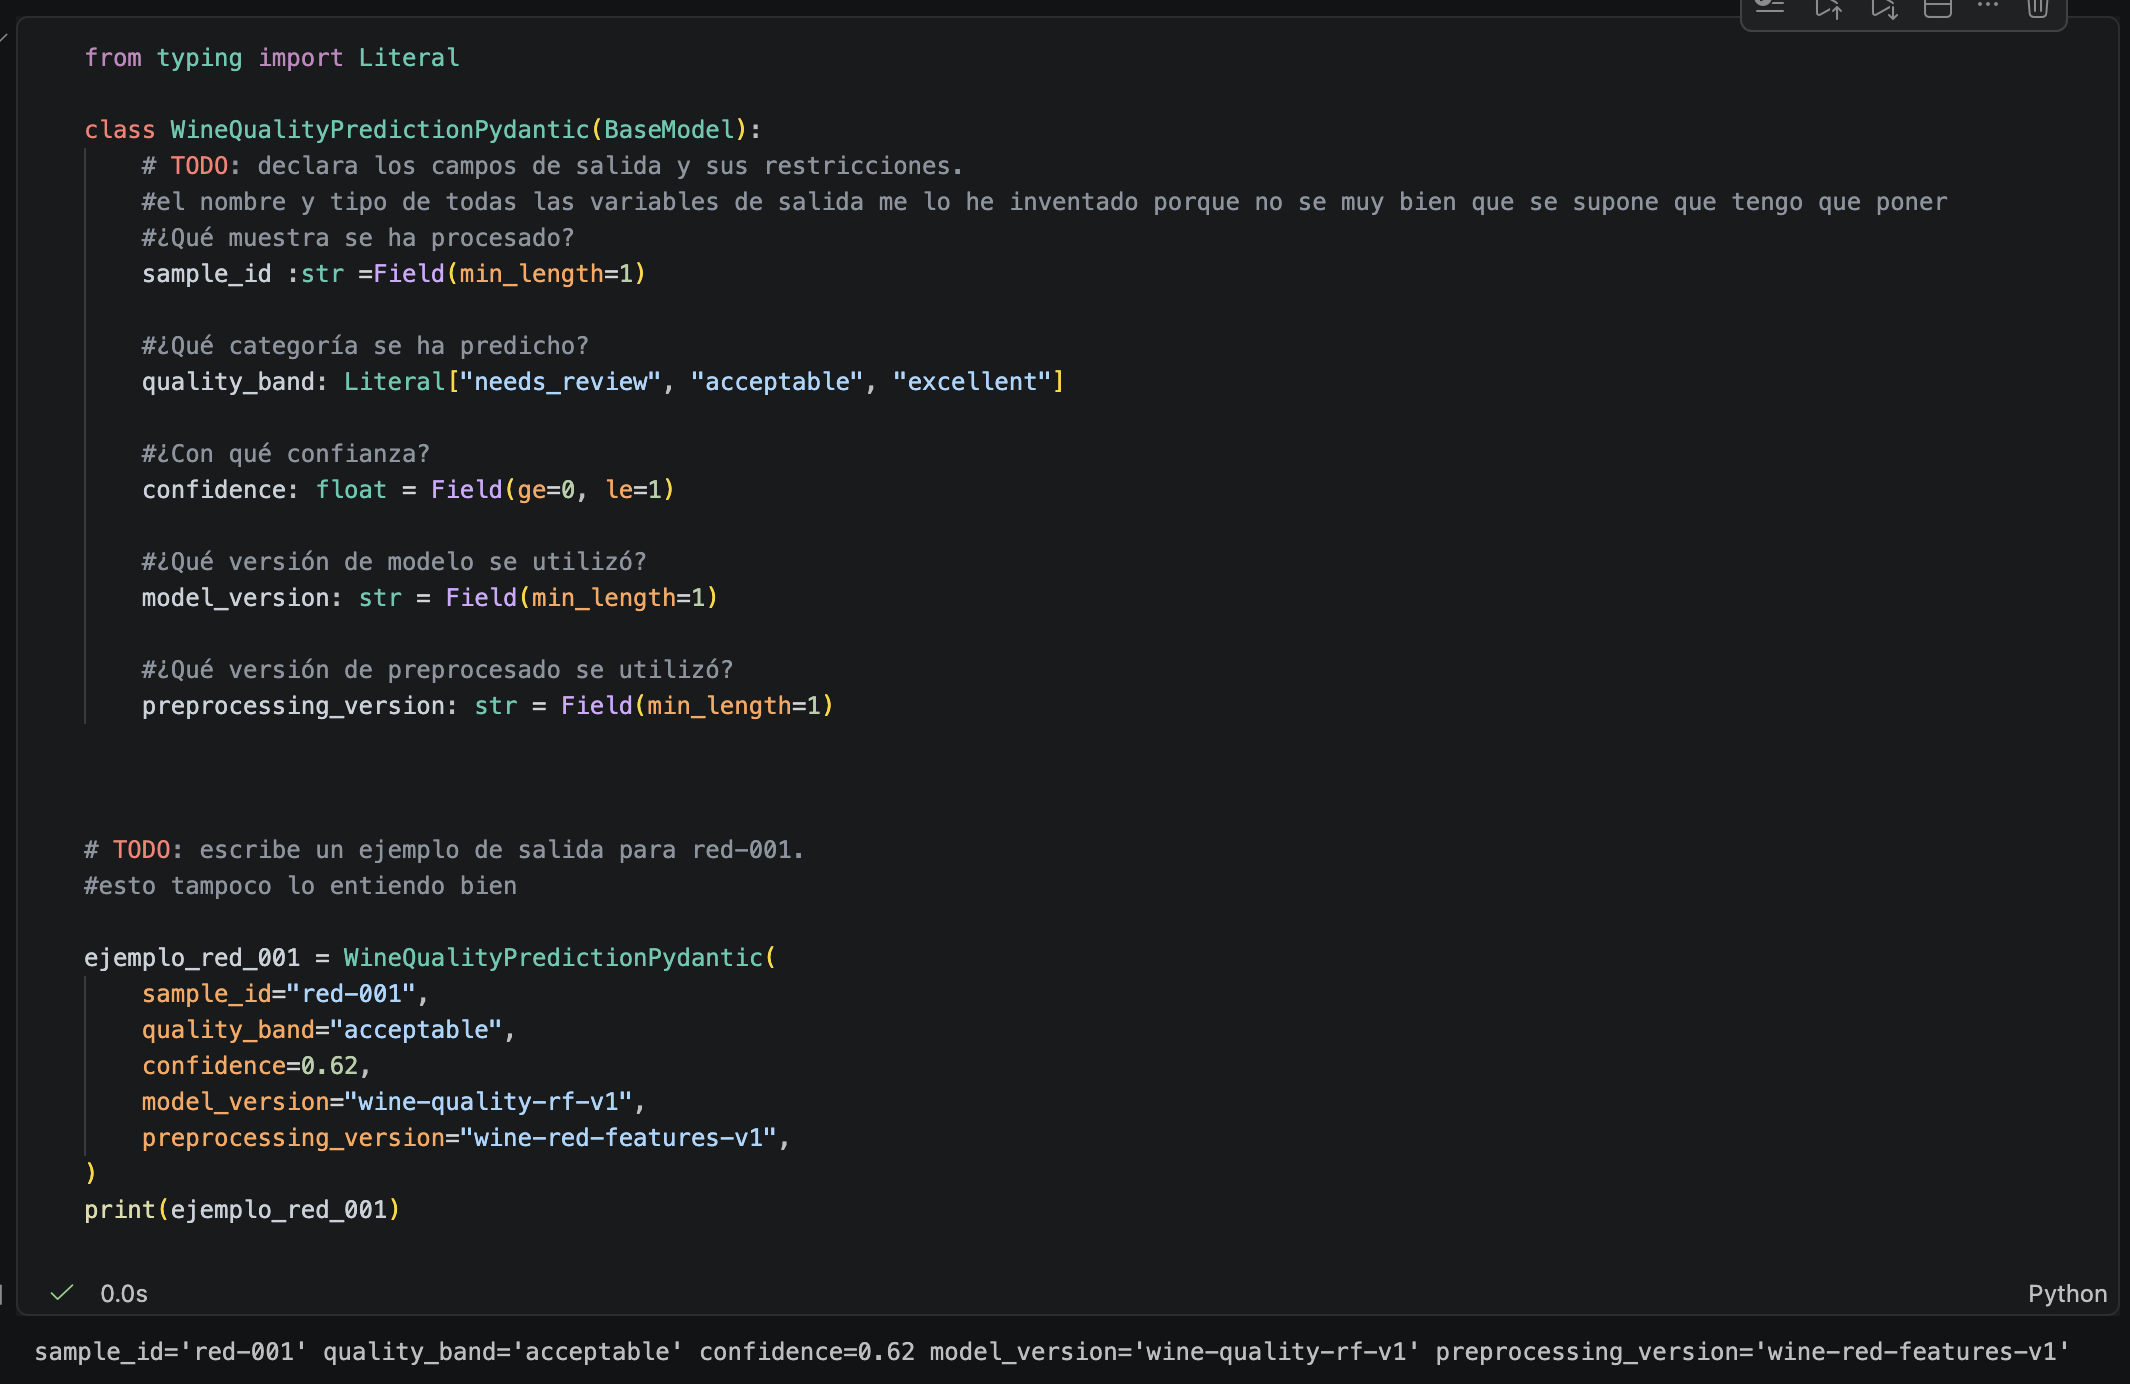

## Diagrama del checkpoint2

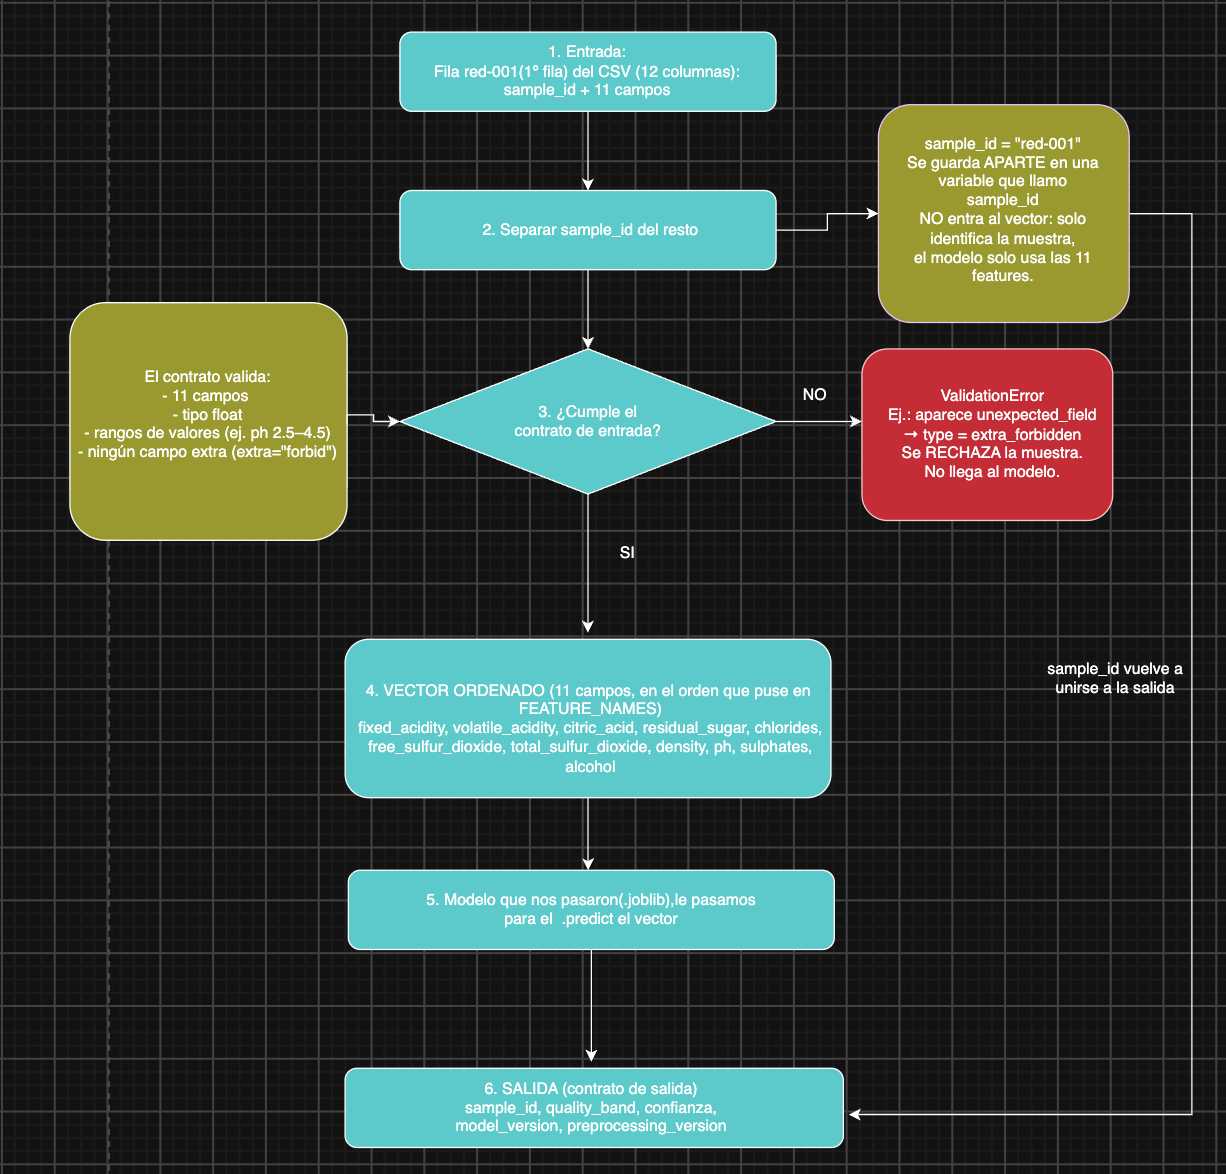

## - Tu plan de implementación para `contracts.py`, `preprocess.py`, `inference.py` y `predict_file.py`.

-contracts.py (validar): aquí van los contratos de entrada y de salida con Pydanti(WineQualityRequestPydantic). Valida una fila ya leída del CSV,mirando que estén los 11 campos, que sean float, que estén dentro de rango y que no haya columnas de más(o lo que definamos en el contrato,esto es enn nuestro ejemplo )

-preprocess.py (preparar): coge la muestra ya validada por los contratos y construye el vector ordenado de 11 números siguiendo el orden de FEATURE_NAMES que definimos nosotros también.sample_id no entra en el vector porque es solo para identificar,no sirve para predecir,lo añadiremos despues al contrato de salida

-inference.py (cargar y predecir): carga el modelo del .joblib que nos han pasado y comprueba que las características que guarda coinciden con FEATURE_NAMES. Si no coinciden, falla antes de predecir. Después le pasa el vector al modelo y devuelve la predicción

-predict_file.py (coordinar): es el script que se ejecuta. Lee el CSV y, fila por fila, llama a contracts, preprocess e inference. Al final escribe predictions.csv.

-¿Cómo evitamos crear un CSV parcial?:Para no dejar un CSV parcial: se validan y predicen todas las filas antes de abrir el archivo de salida, y solo se escribe si todas van bien 

## Criterios de aceptación

1. Orden de las once variables sin sample_id: El vector que le pasamos al modelo tiene 11 números, en el orden de FEATURE_NAMES y sin sample_id. Se comprueba con red-001: tiene que salir [7.4, 0.7, 0.0, 1.9, 0.076, 11.0, 34.0, 0.9978, 3.51, 0.56, 9.4].

2. Rechazo de entradas inválidas antes del modelo: Si una fila trae una columna de más o un valor que no este en el rango (como ph = 67.0), el contrato da un ValidationError y no se llega al modelo, y no se crea ningún archivo de salida a medias. Se comprueba con una copia del CSV con una columna extra: el comando falla y no aparece el archivo de salida.

3. Salida con categoría, confianza y ambas versiones : La salida tiene sample_id, quality_band (needs_review, acceptable o excellent), confidence (entre 0 y 1), model_version y preprocessing_version. Se comprueba abriendo el archivo de salida: están las cinco columnas y las dos versiones aparecen en todas las filas.